# Fase 7 — Explicabilidad y análisis de errores

Se revisaron fases 5 y 6, el protocolo v2, módulos y pipeline, y las convenciones de los notebooks anteriores. Se conserva XGBoost inicial: 300 árboles, profundidad 4, tasa 0,05, submuestreo de filas/columnas 0,8, semilla 42. No se optimiza, calibra ni abre prueba. Umbral 0,5 solo para diagnóstico.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.explainability import run_explainability
tables, verification=run_explainability(ROOT)
print("Scores fase 5 reproducidos:",verification["predicciones_fase_5_reproducidas"])
print("Versiones SHAP/XGBoost:",verification["shap_version"],verification["xgboost_version"])

C:\Users\panio\Documents\Curso\DataScience\proyecto_machineLearning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Reconstruyendo XGBoost inicial, sin optimización.


Scores fase 5 reproducidos: True
Versiones SHAP/XGBoost: 0.54.1 3.4.1


## Importancia y SHAP

La ganancia total suma reducción de objetivo en splits de entrenamiento; se agrega por variable original. SHAP exacto TreeExplainer/tree_path_dependent explica el margen log-odds de XGBoost, con referencia implícita en los árboles de entrenamiento. Sumar base y contribuciones y aplicar sigmoide reconstruye probabilidad. Las contribuciones no son puntos porcentuales ni causas.

Se toman 3000 filas de validación por muestreo aleatorio simple, sin reemplazo y semilla 42, independiente de etiqueta. Se audita composición por hotel, mes proxy y clase. Los cuatro casos locales se explican aparte si no estaban en la muestra y no se añaden al ranking global. Se conserva CSR al calcular SHAP: densificar antes cambiaría el tratamiento de ceros/ausencias del modelo. Solo se densifican valores para colores del gráfico. La suma de dummies preserva el margen; no recalcula un juego Shapley de variables originales.

,original,total_gain,proporcion_gain
0,lead_time,106256.609375,0.325697
1,country,90385.657458,0.277050
2,market_segment,41262.507441,0.126478
3,customer_type,33874.959908,0.103833
4,arrival_date_month,18469.764183,0.056613
5,hotel,10819.005005,0.033162
6,total_nights,8370.643555,0.025658
7,distribution_channel,8259.481354,0.025317
8,meal,4627.532166,0.014184
9,adults,2234.437744,0.006849


,original,mean_abs_group_sum,mean_signed_group_sum,sum_mean_abs_dummies
9,country,1.042501,-0.405589,1.248223
0,lead_time,0.820577,-0.436659,0.820578
13,customer_type,0.503253,0.285152,0.504941
10,market_segment,0.427576,0.011401,0.611474
6,hotel,0.344652,0.016697,0.344820
7,arrival_date_month,0.181617,-0.040635,0.268933
11,distribution_channel,0.085927,-0.010606,0.110424
1,total_nights,0.073706,-0.014041,0.073706
8,meal,0.034761,-0.007540,0.051876
12,reserved_room_type,0.033207,0.003865,0.039972


,dimension,grupo,n_validacion,n_muestra,proporcion_validacion,proporcion_muestra
0,hotel,Resort Hotel,5541,928,0.306183,0.309333
1,hotel,City Hotel,12556,2072,0.693817,0.690667
2,is_canceled,0,10344,1762,0.571586,0.587333
3,is_canceled,1,7753,1238,0.428414,0.412667
4,mes_reserva_proxy,2016-07,2925,483,0.161629,0.161000
5,mes_reserva_proxy,2016-08,3245,508,0.179311,0.169333
6,mes_reserva_proxy,2016-09,3656,627,0.202022,0.209000
7,mes_reserva_proxy,2016-10,3018,508,0.166768,0.169333
8,mes_reserva_proxy,2016-11,3112,527,0.171962,0.175667
9,mes_reserva_proxy,2016-12,2141,347,0.118307,0.115667


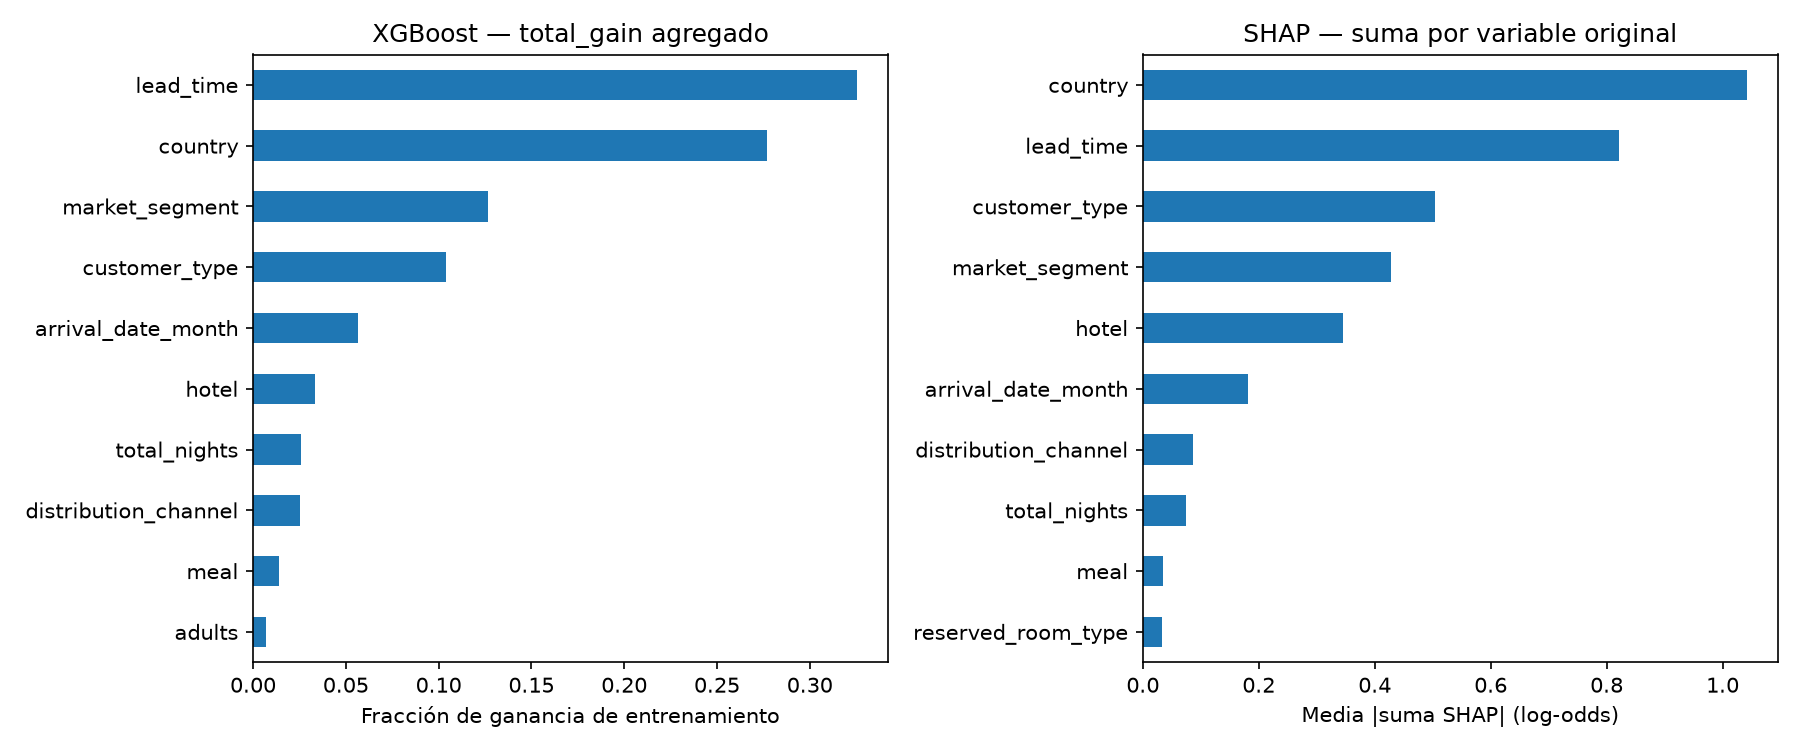

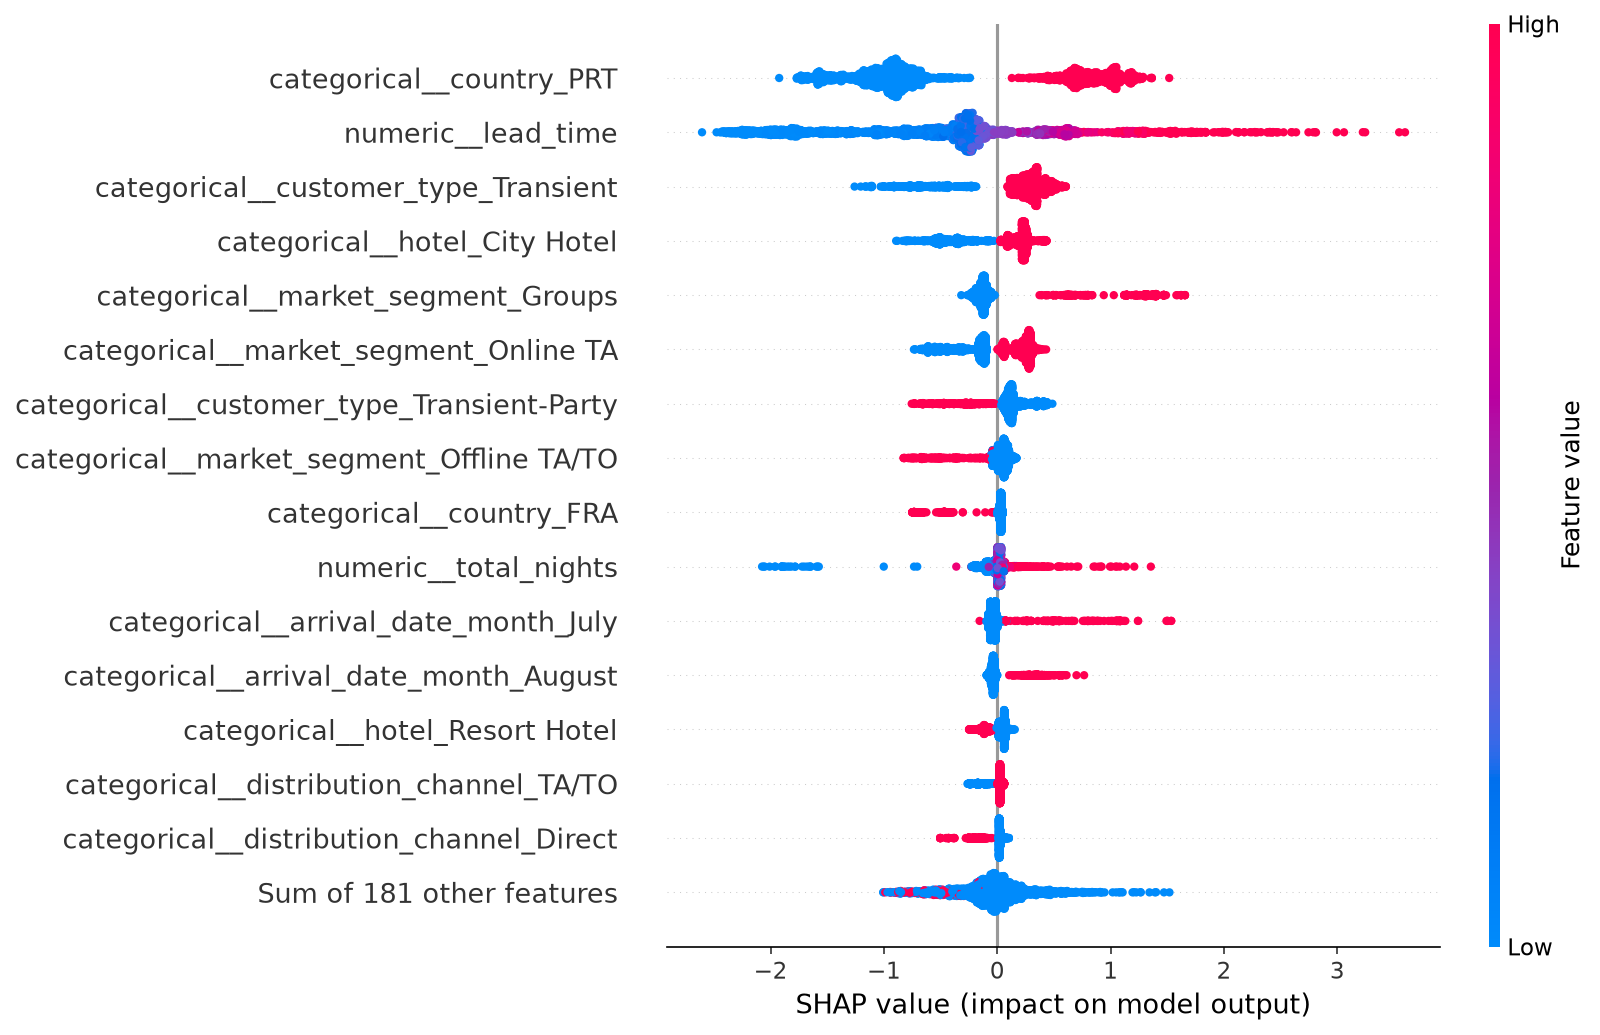

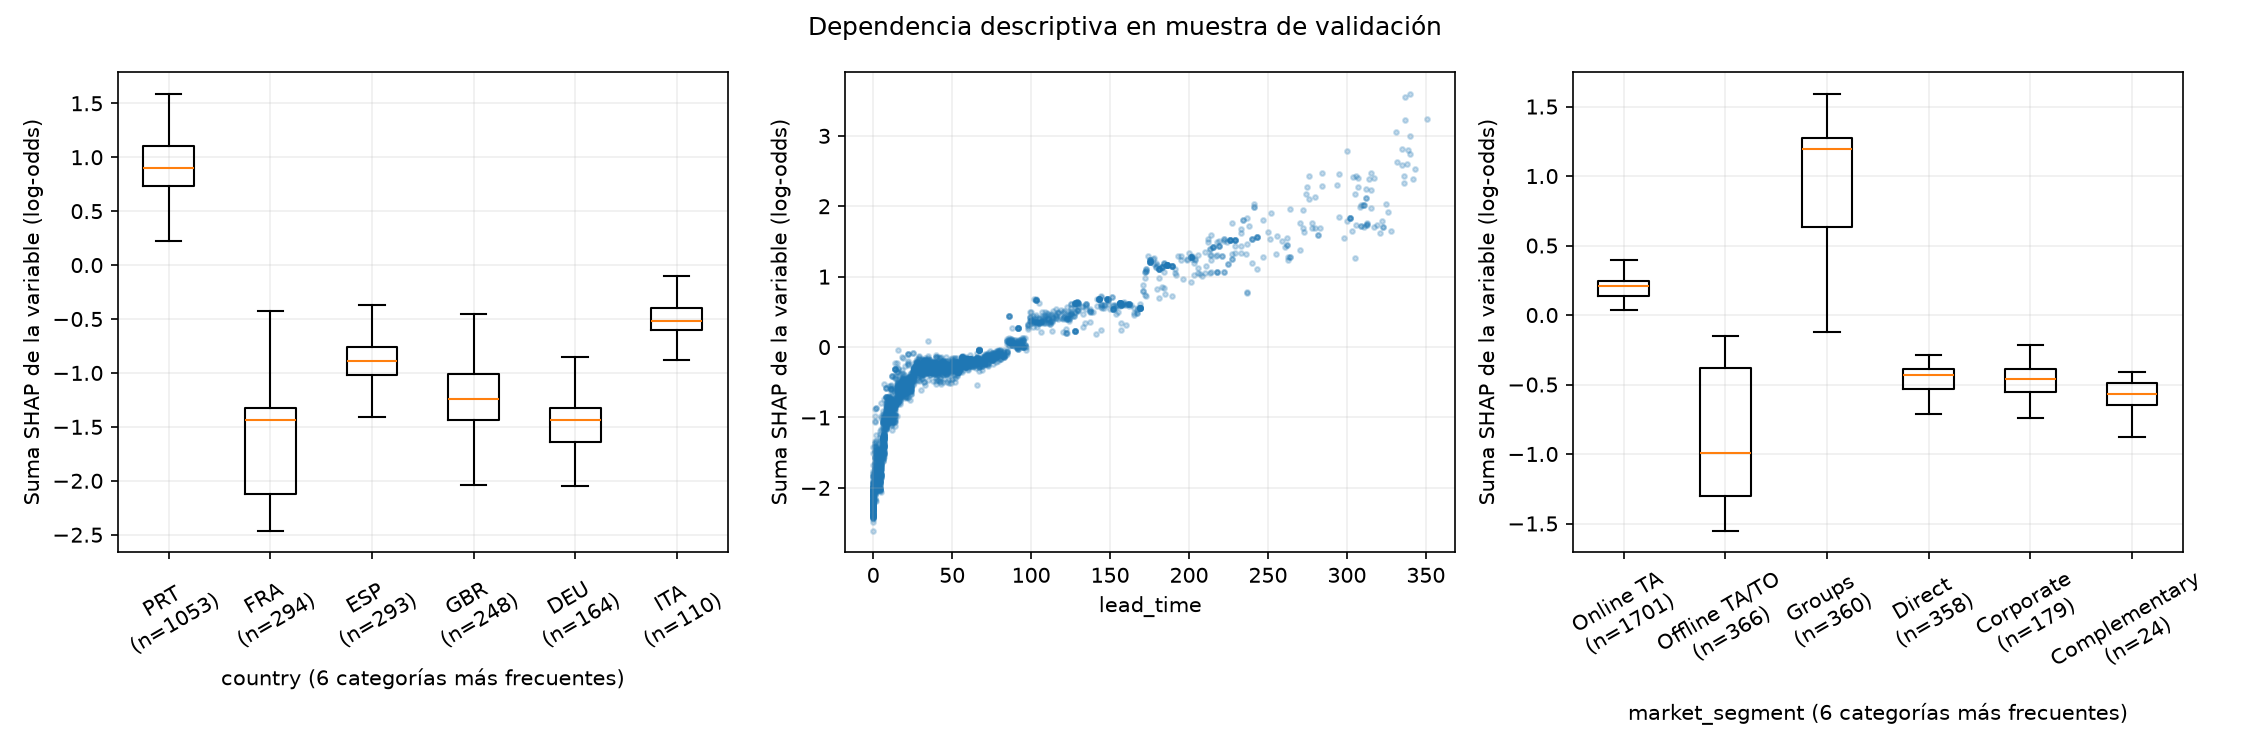

In [2]:
display(tables["gain_originales"].head(10))
display(tables["shap_global"].head(10))
display(tables["muestra_perfil"])
for name in ["importancias","shap_resumen","dependencias"]:
 display(Image(filename=str(ROOT/f"reports/figures/explicabilidad_7_{name}.png")))

## Explicaciones locales

Un caso con probabilidad mediana dentro de TP, TN, FP y FN, desempate por orden original. Ejemplos ilustrativos, no explicaciones de todos los errores. Solo datos de reserva y referencias técnicas locales; no se exportan nombres, contactos, agente o empresa. País se omite en el ejemplo individual. SHAP explica el score del modelo, no por qué el huésped cancela.

,caso,real,probabilidad,base_log_odds,margen,margen_reconstruido,hotel,lead_time,market_segment,distribution_channel,arrival_date_month
0,TP,1,0.876274,-0.30405,1.957605,1.957605,City Hotel,169.0,Offline TA/TO,TA/TO,June
1,TN,0,0.125048,-0.30405,-1.945468,-1.945468,City Hotel,14.0,Direct,Direct,August
2,FP,0,0.587126,-0.30405,0.352097,0.352097,City Hotel,31.0,Corporate,Corporate,November
3,FN,1,0.317130,-0.30405,-0.766995,-0.766994,City Hotel,95.0,Groups,TA/TO,November


TP


,caso,variable,valor,shap_log_odds
9,TP,country,categoría omitida en ejemplo local,1.284220
13,TP,customer_type,Transient,0.565508
0,TP,lead_time,169.0,0.549369
10,TP,market_segment,Offline TA/TO,-0.377824
6,TP,hotel,City Hotel,0.225422
7,TP,arrival_date_month,June,-0.106312


TN


,caso,variable,valor,shap_log_odds
23,TN,country,categoría omitida en ejemplo local,-1.268013
14,TN,lead_time,14.0,-0.844953
24,TN,market_segment,Direct,-0.518143
17,TN,children,2.0,0.401117
27,TN,customer_type,Transient,0.375585
20,TN,hotel,City Hotel,0.340097


FP


,caso,variable,valor,shap_log_odds
37,FP,country,categoría omitida en ejemplo local,0.967460
41,FP,customer_type,Transient,0.407941
38,FP,market_segment,Corporate,-0.386701
28,FP,lead_time,31.0,-0.283995
34,FP,hotel,City Hotel,0.195046
39,FP,distribution_channel,Corporate,-0.145279


FN


,caso,variable,valor,shap_log_odds
55,FN,customer_type,Transient-Party,-1.646770
51,FN,country,categoría omitida en ejemplo local,1.060616
52,FN,market_segment,Groups,0.484481
49,FN,arrival_date_month,November,-0.175541
44,FN,adults,1.0,-0.119959
43,FN,total_nights,1.0,-0.113991


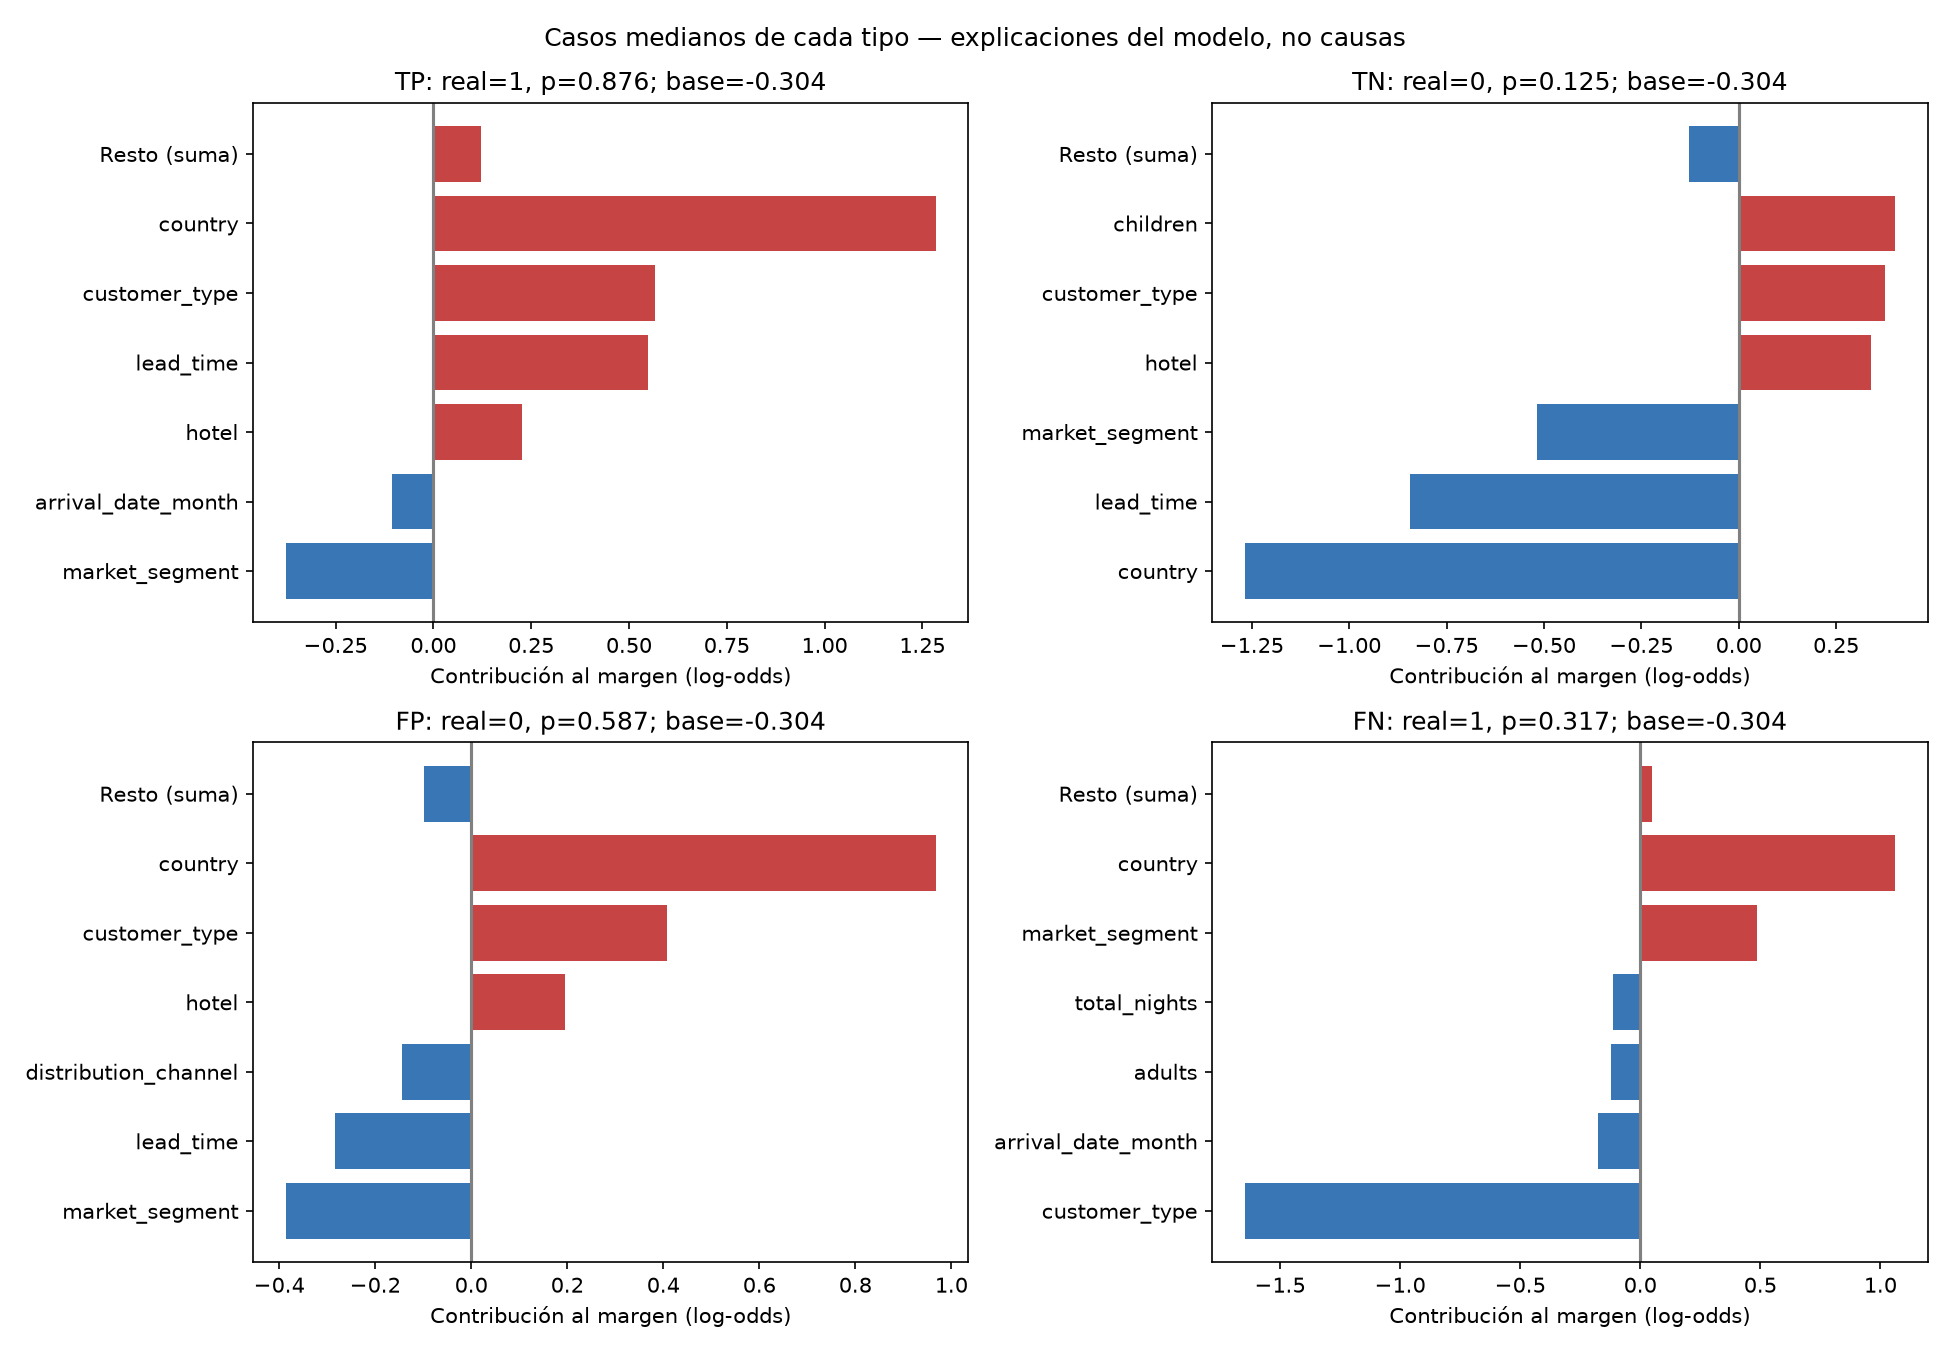

In [3]:
display(tables["casos"].drop(columns="meta_row_id"))
for label in ["TP","TN","FP","FN"]:
 print(label)
 local=tables["contribuciones_locales"].query("caso == @label").copy()
 display(local.reindex(local.shap_log_odds.abs().sort_values(ascending=False).index).head(6))
display(Image(filename=str(ROOT/"reports/figures/explicabilidad_7_locales.png")))

## Errores, segmentos y estabilidad

Solo validación completa. Se comparan tamaños, prevalencia, probabilidad media, AUC, precision/recall/F1, FP/FN y tasas por clase: FPR=FP/no canceladas y FNR=FN/canceladas. Se marcan como insuficientes los segmentos con menos de 100 filas o menos de 30 de alguna clase; el criterio es descriptivo y no prueba significación. Canales, mercados, hotel, mes de llegada, tipo de cliente y antelación son análisis marginales solapados; no se suman entre dimensiones. Mes proxy de reserva sirve para estabilidad temporal, no como predictor.

,dimension,grupo,n,no_canceladas,canceladas,tasa_cancelacion,probabilidad_media,brecha_calibracion,brier,roc_auc,...,recall,f1,tn,fp,fn,tp,fpr,fnr,tasa_error,suficiente_descriptivo
0,hotel,City Hotel,12556,6596,5960,0.4747,0.4195,-0.0552,0.1528,0.8667,...,0.5931,0.7050,6062,534,2425,3535,0.0810,0.4069,0.2357,True
1,hotel,Resort Hotel,5541,3748,1793,0.3236,0.2147,-0.1088,0.1615,0.8463,...,0.3575,0.5002,3619,129,1152,641,0.0344,0.6425,0.2312,True
2,antelacion_grupo,0-7,3922,3532,390,0.0994,0.1121,0.0127,0.0881,0.6774,...,0.0487,0.0868,3503,29,371,19,0.0082,0.9513,0.1020,True
3,antelacion_grupo,181+,1540,0,1540,1.0000,0.7866,-0.2134,0.1045,NaN,...,0.8565,0.9227,0,0,221,1319,NaN,0.1435,0.1435,False
4,antelacion_grupo,31-90,6058,3316,2742,0.4526,0.3556,-0.0970,0.1944,0.7895,...,0.4216,0.5479,2994,322,1586,1156,0.0971,0.5784,0.3150,True
5,antelacion_grupo,8-30,4167,2969,1198,0.2875,0.2691,-0.0184,0.1832,0.7111,...,0.2237,0.3223,2772,197,930,268,0.0664,0.7763,0.2705,True
6,antelacion_grupo,91-180,2410,527,1883,0.7813,0.6350,-0.1463,0.1520,0.8477,...,0.7509,0.8288,412,115,469,1414,0.2182,0.2491,0.2423,True
34,mes_reserva_proxy,2016-07,2925,1856,1069,0.3655,0.3638,-0.0017,0.1929,0.7390,...,0.4369,0.5195,1594,262,602,467,0.1412,0.5631,0.2954,True
35,mes_reserva_proxy,2016-08,3245,2031,1214,0.3741,0.3197,-0.0544,0.1697,0.8090,...,0.4390,0.5682,1902,129,681,533,0.0635,0.5610,0.2496,True
36,mes_reserva_proxy,2016-09,3656,2320,1336,0.3654,0.2817,-0.0837,0.1629,0.8412,...,0.3862,0.5271,2214,106,820,516,0.0457,0.6138,0.2533,True


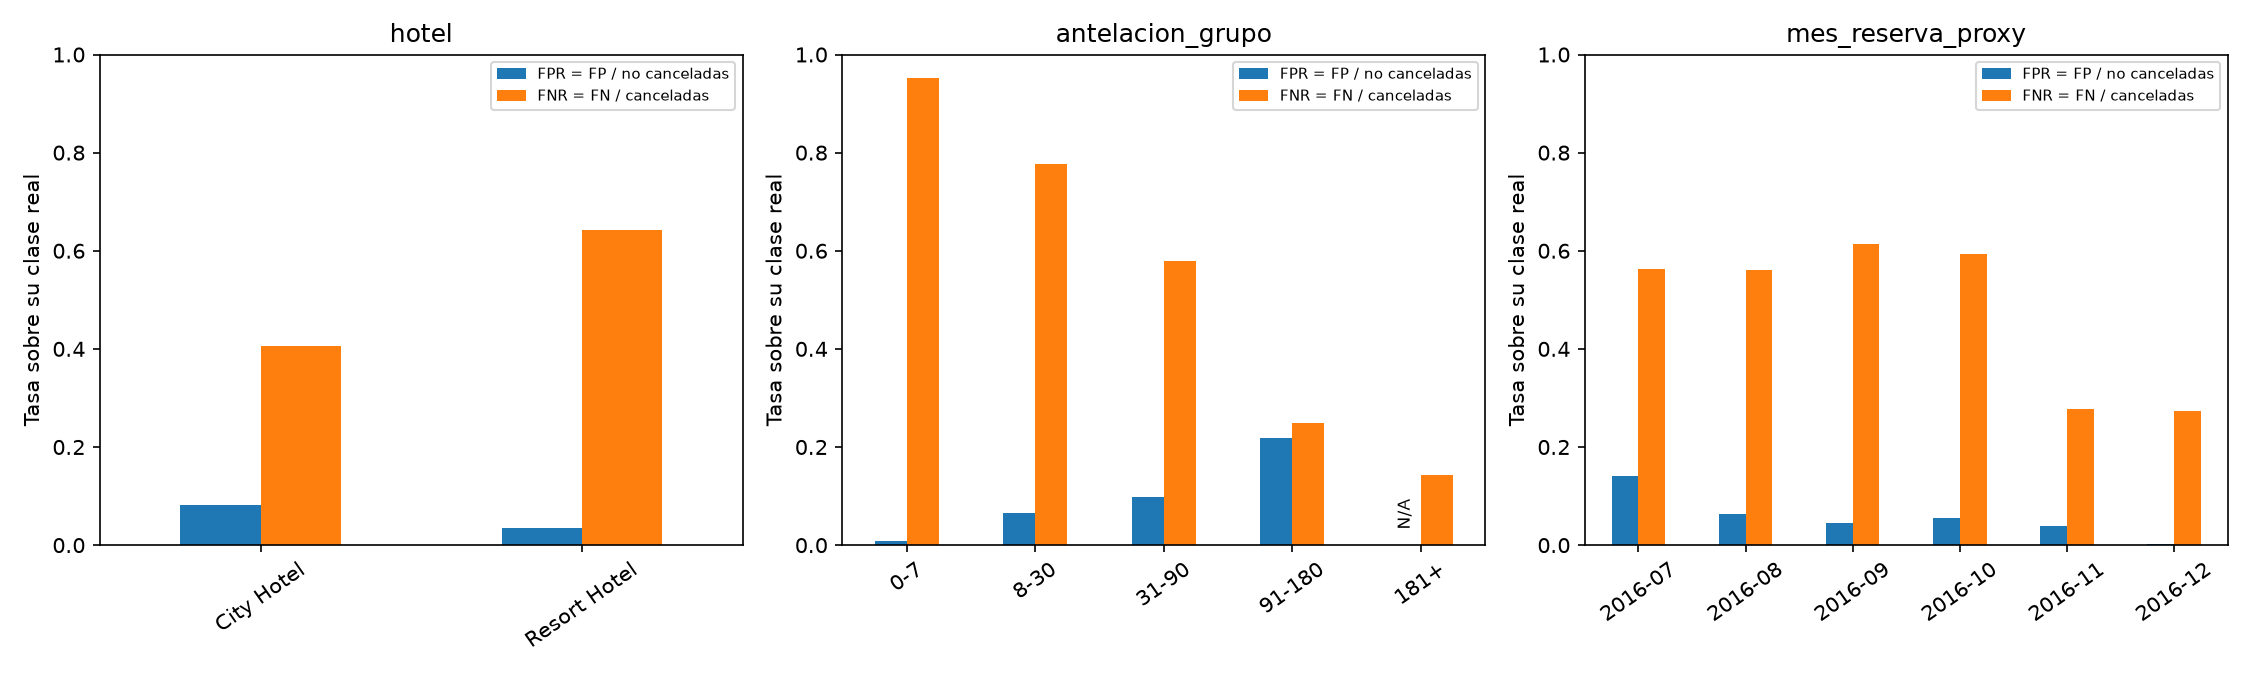

In [4]:
segments=tables["segmentos"]
display(segments[segments.dimension.isin(["hotel","antelacion_grupo","mes_reserva_proxy"])].round(4))
display(Image(filename=str(ROOT/"reports/figures/explicabilidad_7_errores.png")))

## Calibración y decisiones

Se analiza Brier y diez intervalos de probabilidad por hotel. Los bins con menos de 100 filas se señalan, sin afirmar precisión estadística por superar ese umbral. No se ajusta calibrador. Para una fase posterior: reservar un bloque temporal dentro de train separado de selección de parámetros, ajustar el modelo base solo antes del bloque con madurez respetada, calibrar scores fuera de ajuste y evaluar después en un periodo realmente no utilizado. Los folds ya usados para tuning no son automáticamente independientes.

Discriminación, calibración y acción de negocio son distintas. Podría estudiarse contacto preventivo o solicitud de confirmación con revisión humana y capacidad real; nunca penalizaciones automáticas. La validación elegible tiene sesgo por disponibilidad, duplicados y snapshots iniciales no acreditados; SHAP no corrige estas limitaciones.

,grupo,n,tasa_cancelacion,probabilidad_media,brecha_calibracion,brier
0,City Hotel,12556,0.474673,0.419491,-0.055183,0.152778
1,Resort Hotel,5541,0.323588,0.214746,-0.108841,0.161531


,hotel,bin,inferior,superior,n,probabilidad_media,tasa_observada,n_al_menos_100
0,Todos,0,0.0,0.1,4447,0.0462,0.0594,True
1,Todos,1,0.1,0.2,2678,0.1455,0.2535,True
2,Todos,2,0.2,0.3,2193,0.2508,0.3242,True
3,Todos,3,0.3,0.4,2287,0.3521,0.4556,True
4,Todos,4,0.4,0.5,1653,0.4475,0.5330,True
5,Todos,5,0.5,0.6,1178,0.5434,0.6902,True
6,Todos,6,0.6,0.7,726,0.6475,0.7466,True
7,Todos,7,0.7,0.8,520,0.7486,0.8288,True
8,Todos,8,0.8,0.9,551,0.8576,0.9583,True
9,Todos,9,0.9,1.0,1864,0.9630,0.9989,True


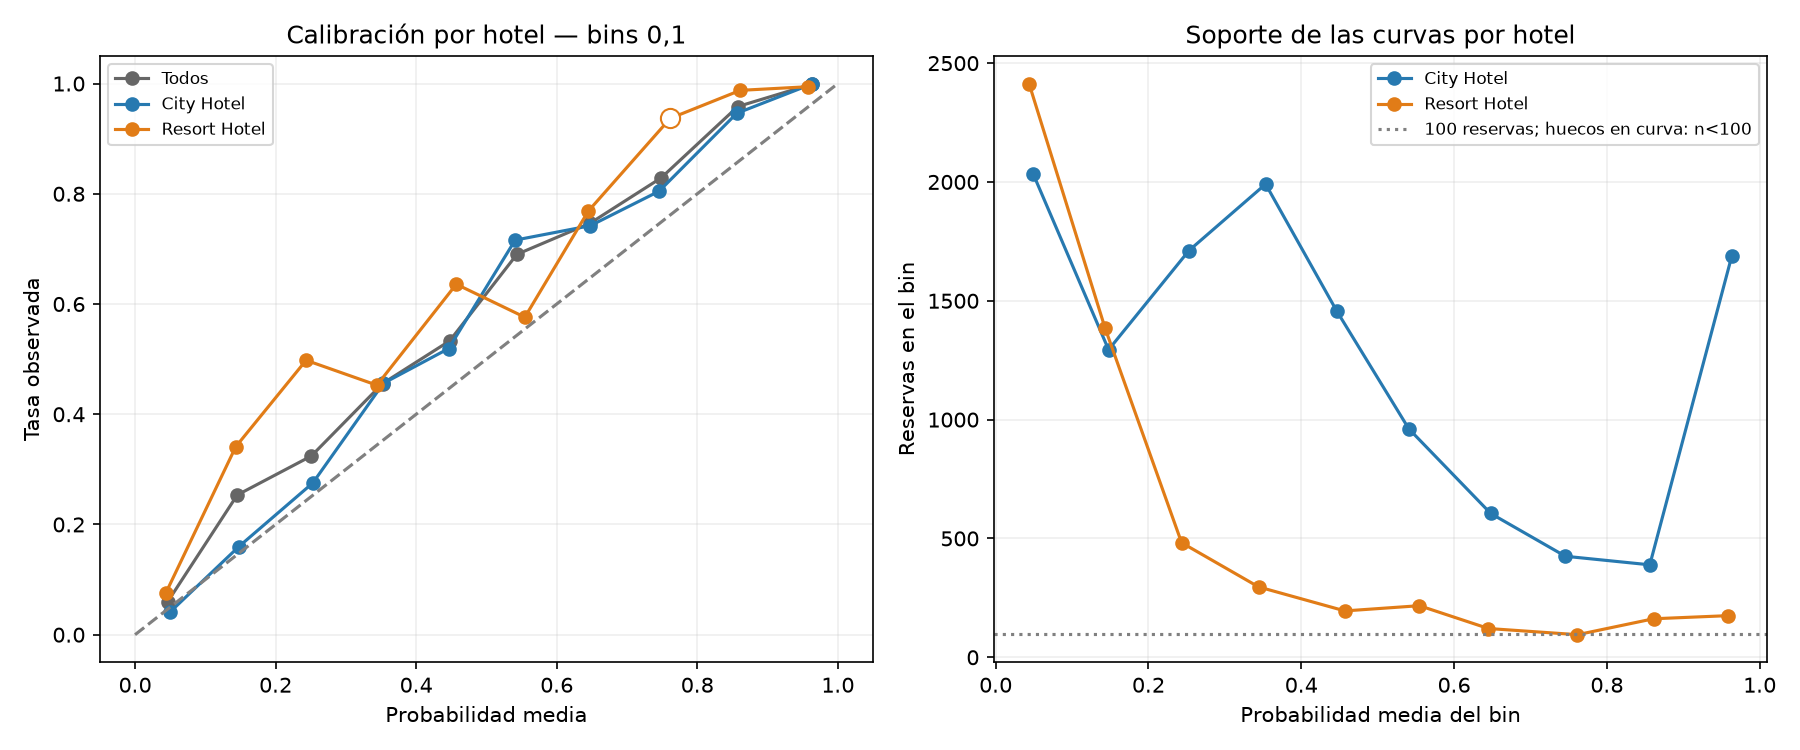

In [5]:
display(segments[segments.dimension.eq("hotel")][["grupo","n","tasa_cancelacion","probabilidad_media","brecha_calibracion","brier"]])
display(tables["calibracion_bins"].round(4))
display(Image(filename=str(ROOT/"reports/figures/explicabilidad_7_calibracion.png")))

## Verificaciones y cierre

Se conserva original, preparado, manifiesto, informes y módulos previos. La muestra SHAP contiene solo validación y el pipeline se ajustó solo con entrenamiento. La correspondencia de 196 columnas se construye desde el encoder y se verifica aditividad y sigmoide. Consultar fase_7_explicabilidad.md para hallazgos y recomendaciones. No se avanza a evaluación final.

## Hallazgos y recomendación

País, antelación, tipo de cliente y mercado son las contribuciones agrupadas SHAP más importantes; explican la función, no causas. Ejemplos medianos: TP p=0,876 (antelación/cliente aportan al alza), TN p=0,125 (antelación corta/Direct a la baja), FP p=0,587 (aportes al alza no implican cancelación real), FN p=0,317 (Transient-Party reduce el margen pese a otros aportes positivos).

Resort tiene FNR 64,25% frente a 40,69% en City. Online TA acumula 2665 FN y 542 FP por su volumen; Direct omite 88,70% de sus cancelaciones. Con 0–7 días se omite 95,13% de cancelaciones, aunque son pocas dentro de su segmento. Los grupos pequeños o con una sola clase se marcan y no se comparan por AUC.

**Advertencia metodológica:** las 3917 reservas con llegada desde enero de 2017 presentes en validación son todas canceladas y aportan 75,8% de los TP. En las 14180 con llegada anterior al corte, recall 26,33% y AUC 0,7721: la selección por disponibilidad pesa mucho en las métricas agregadas. La descomposición es auditoría, no un cambio de particiones.

Brier global 0,155458. Probabilidad media 35,68% frente a 42,84% observado; brecha de infrapredicción 5,52 puntos en City y 10,88 en Resort. No se ajusta calibrador. Antes de evaluación final, revisar este sesgo, documentar snapshots/seguimiento y diseñar calibración temporal independiente, manteniendo prueba cerrada y decisiones sin uso automático. No se modifica protocolo ni se avanza de fase.

In [6]:
import unittest,io
from src.comparison import sha
log=io.StringIO()
result=unittest.TextTestRunner(stream=log).run(unittest.defaultTestLoader.discover(str(ROOT/"tests")))
print(log.getvalue())
assert result.wasSuccessful()
for path,expected in verification["datos_anteriores_intactos"].items(): assert sha(ROOT/path)==expected,path
assert verification["prueba_transformada_predicha_evaluada"] is False
print("Pruebas superadas:",result.testsRun)
print("Fin exclusivo de fase 7.")

..............................
----------------------------------------------------------------------
Ran 30 tests in 0.520s

OK

Pruebas superadas: 30
Fin exclusivo de fase 7.
